# Project 2: Shrinking High Schools and the Cost of Consolidation in Montana
Ben Oliver & Chris Jenemann · GDS 502 · October 2026

### Hypothesis
Enrollment decline among Montana's public high schools is spatially clustered (not random) and concentrated in rural central Montana. Because those schools are far apart on a sparse road network, consolidating them would impose an order of magnitude more drive time on residents than consolidating an urban school, so enrollment decline alone is not a sufficient argument for rural consolidation.

### Data
| Dataset | Source | Use |
|---|---|---|
| High school enrollment 2003–2023 | Montana OPI GEMS | 5/10/20-yr % change per school |
| Urban-centric locale codes 2005–06 | NCES Common Core of Data | urban/rural class per school (View 3) |
| Secondary & Unified school districts, school points | Montana State Library | district boundaries, school locations |
| Drivable road network | OpenStreetMap via OSMnx | shortest-path drive time |
| Population on H3 hexagons (2023) | Kontur | population weighting of drive times |

### Pipeline
1. Statewide: join enrollment to school points, build row-standardized k=5 KNN spatial weights, compute the spatial lag, global Moran's I and local Moran's I (LISA) (Rey et al., *Geographic Data Science with Python*, ch. 4, 6, 7).
2. Urban control (Helena): OSM road network $\to$ Dijkstra drive time to the nearest school, before and after closing Helena High; overlay (clip) Kontur population hexes to the district and weight the results by population.
3. Rural case (central MT): the same pipeline on four adjacent districts that LISA flags as a significant cold spot, under four "all into one school" scenarios.

The notebook documents nine revised views (QGIS exploration $\to$ final view). Each is followed by a short critique of what works, what doesn't, and what the next revision changes.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import libpysal
from libpysal.weights import KNN, lag_spatial
from esda.moran import Moran, Moran_Local
import folium
from branca.element import MacroElement
from folium.template import Template
from shapely import make_valid
from rasterio.plot import show
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

# map furniture: scale bar (lower left), north arrow (upper left), cartographer box (below the figure, under the rightmost plot)
# assumes a projected crs in meters
def add_map_furniture(ax, north_x=0.05):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    target = (x1 - x0) / 5
    mag = 10 ** np.floor(np.log10(target))
    length = max(m * mag for m in (1, 2, 5) if m * mag <= target)
    ax.add_artist(AnchoredSizeBar(ax.transData, length, f"{length / 1000:g} km", "lower left",
                                  pad=0.4, sep=4, size_vertical=(y1 - y0) / 250, frameon=True))
    ax.annotate("N", xy=(north_x, 0.97), xytext=(0, -35), xycoords="axes fraction", textcoords="offset points",
                ha="center", va="center", fontsize=12, fontweight="bold",
                arrowprops=dict(facecolor="black", width=4, headwidth=12, headlength=10))

def add_cartographer_box(fig, crs, sources):
    # right-align with the rightmost plot (equal-aspect maps can be narrower than the figure)
    for a in fig.axes:
        a.apply_aspect()
    right = max(a.get_position().x1 for a in fig.axes)
    # sit just under the lowest drawn element (e.g. the colorbar label), not the figure edge
    r = fig.canvas.get_renderer()
    bottom = min(a.get_tightbbox(r).y0 for a in fig.axes) / fig.bbox.height
    fig.text(right, bottom - 0.01,
             f"Cartographers: Ben Oliver & Chris Jenemann, Date: October 2026\n"
             f"Projection: {crs.name} (EPSG:{crs.to_epsg()})\nSources: {sources}",
             ha="right", va="top", fontsize=7,
             bbox=dict(boxstyle="square,pad=0.4", facecolor="white", edgecolor="black", linewidth=0.8))

---
## Part 1: Is enrollment decline spatially clustered?

### View 1: QGIS exploratory map of 20-year enrollment change
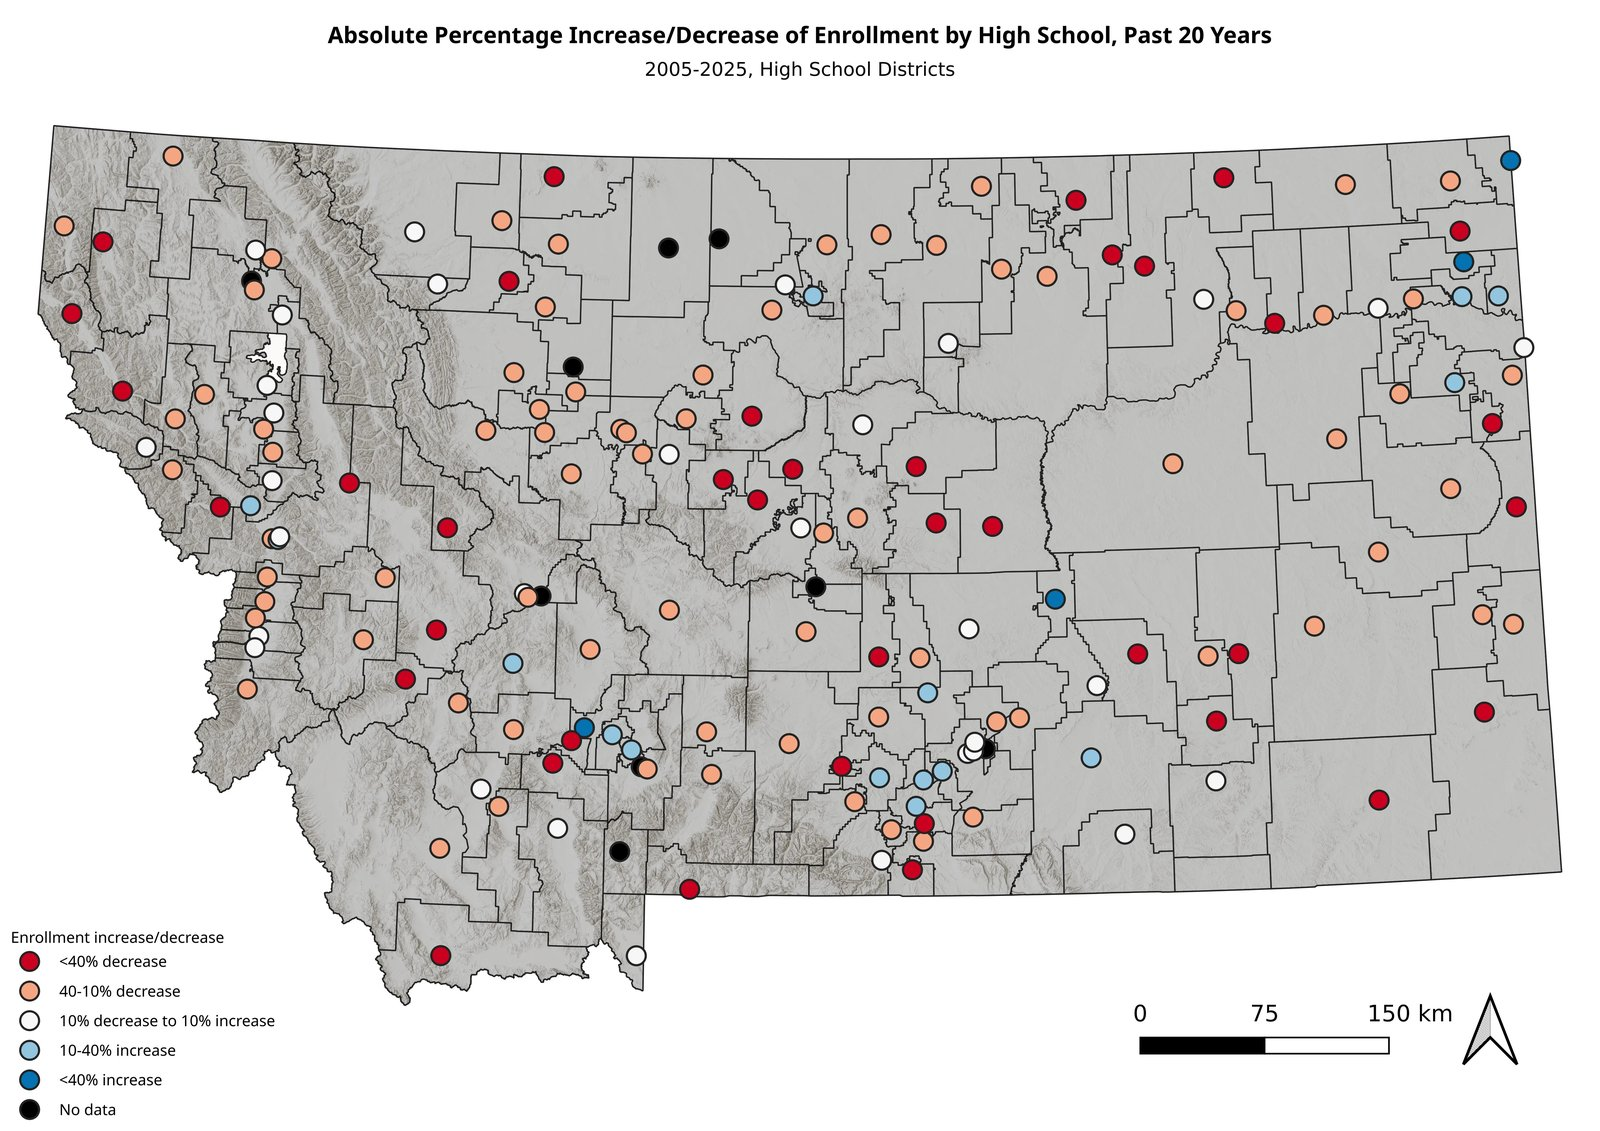

*QGIS project: `view-1-qgis.qgz`. Joined OPI enrollment table to MSL school points, graduated symbols over secondary + unified districts on a hillshade.*

Working: A diverging 5-class scheme centered on a ±10% "stable" class is the right choice for change data with a meaningful zero. Map furniture (scale bar, north arrow, legend) is complete, and the hillshade gives terrain context.

Needs attention:
- The legend is wrong: "<40% decrease" should be ">40% decrease", and the title says 2005–2025 when the data are 2003–2023. That's a fidelity problem.
- Black "No data" symbols are the darkest marks on the page. They draw the eye to the *least* informative points (figure-ground is inverted).
- Heavy black district outlines plus hillshade compete with the data. Much of the ink is not data-ink.
- We can *see* lots of red, but we can't tell whether decline is clustered or just everywhere. Eyeballing a map is not a test.

Next revision: Move to Python and quantify spatial structure with spatial weights, the spatial lag, and Moran's I.

### View 2: First Python spatial-lag map + Moran scatterplot
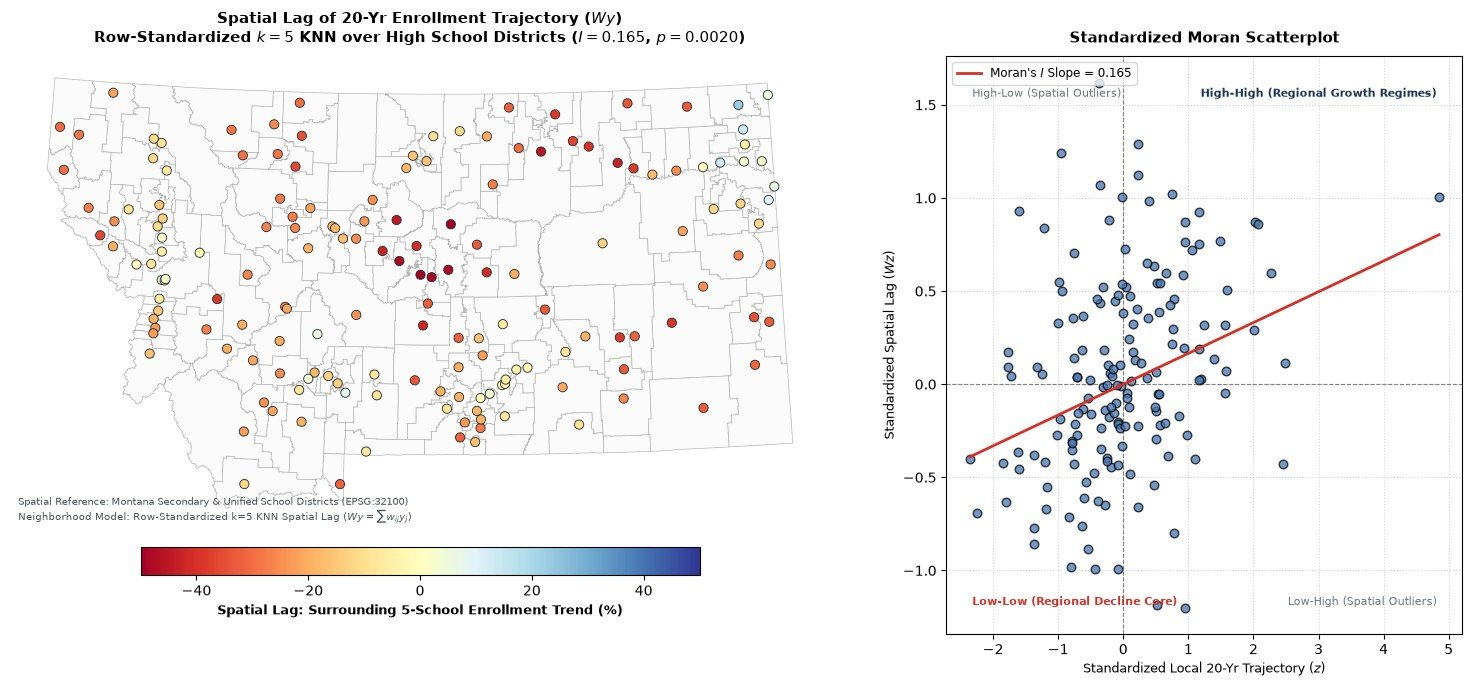

Working: Schools are points and secondary/unified districts overlap, so contiguity weights don't apply. We used row-standardized k=5 KNN weights instead, so each school's spatial lag $Wy$ is the average trend of its 5 nearest neighbors. Global Moran's $I = 0.165$ ($p < 0.01$, 999 permutations) shows that clustering is real. The diverging `RdYlBu` map uses `TwoSlopeNorm` so 0% sits at the neutral yellow.

Needs attention:
- The quadrant labels are swapped. With the school on x and its neighbors on y, bottom-right is High-Low, not Low-High. The Moran's I legend also covers one of them.
- The map is not self-documenting: no scale bar, no north arrow, no data sources. The small grey annotation text in the corner is redundant with the title.
- Every scatter point is the same blue, so color carries no information. Bold titles are visually heavier than the data.

Next revision: Add map furniture and a cartographer/source box, fix the quadrant labels, and use point color for a real variable.

In [2]:
# combine all high school districts to one file
path_sec = "MontanaSchoolDistricts_shp/MontanaSchoolDistricts_shp/Secondary.shp"
path_uni = "MontanaSchoolDistricts_shp/MontanaSchoolDistricts_shp/Unified.shp"

gdf_sec = gpd.read_file(path_sec)
gdf_uni = gpd.read_file(path_uni)
gdf_districts = pd.concat([gdf_sec, gdf_uni], ignore_index=True)

target_crs = "EPSG:32100"
if gdf_districts.crs != target_crs:
    gdf_districts = gdf_districts.to_crs(target_crs)

df_schools = pd.read_csv("public_highschools_clean.csv", dtype={"ncessch": str})

gdf_schools = gpd.GeoDataFrame(
    df_schools,
    geometry=gpd.points_from_xy(df_schools.longitude, df_schools.latitude),
    crs="EPSG:4326"
    )

gdf_schools = gdf_schools.to_crs("EPSG:32100")

# nces 2005-06 urban-centric locale code (fixed-width file: ncessch in cols 1-12, ulocale in cols 183-184)
locale = pd.read_fwf("sl051bkn.dat", colspecs=[(0, 12), (182, 184)], names=["ncessch", "ulocale"],
                     dtype=str, encoding="latin-1")
gdf_schools = gdf_schools.merge(locale, on="ncessch", how="left")

# remove nans and infs from the pct_change_20yr column
gdf_schools = gdf_schools.replace([np.inf, -np.inf], np.nan)
gdf_schools = gdf_schools.dropna(subset=['pct_change_20yr', 'geometry']).reset_index(drop=True)


w_knn5 = KNN.from_dataframe(gdf_schools, k=5)
w_knn5.transform = 'R'

# compute spatial lag
gdf_schools['lag_pct_change'] = lag_spatial(w_knn5, gdf_schools['pct_change_20yr'])

# morans i
moran = Moran(gdf_schools['pct_change_20yr'], w_knn5)

# standardize
y_raw = gdf_schools['pct_change_20yr']
y_std = (y_raw - y_raw.mean()) / y_raw.std()
lag_std = lag_spatial(w_knn5, y_std)

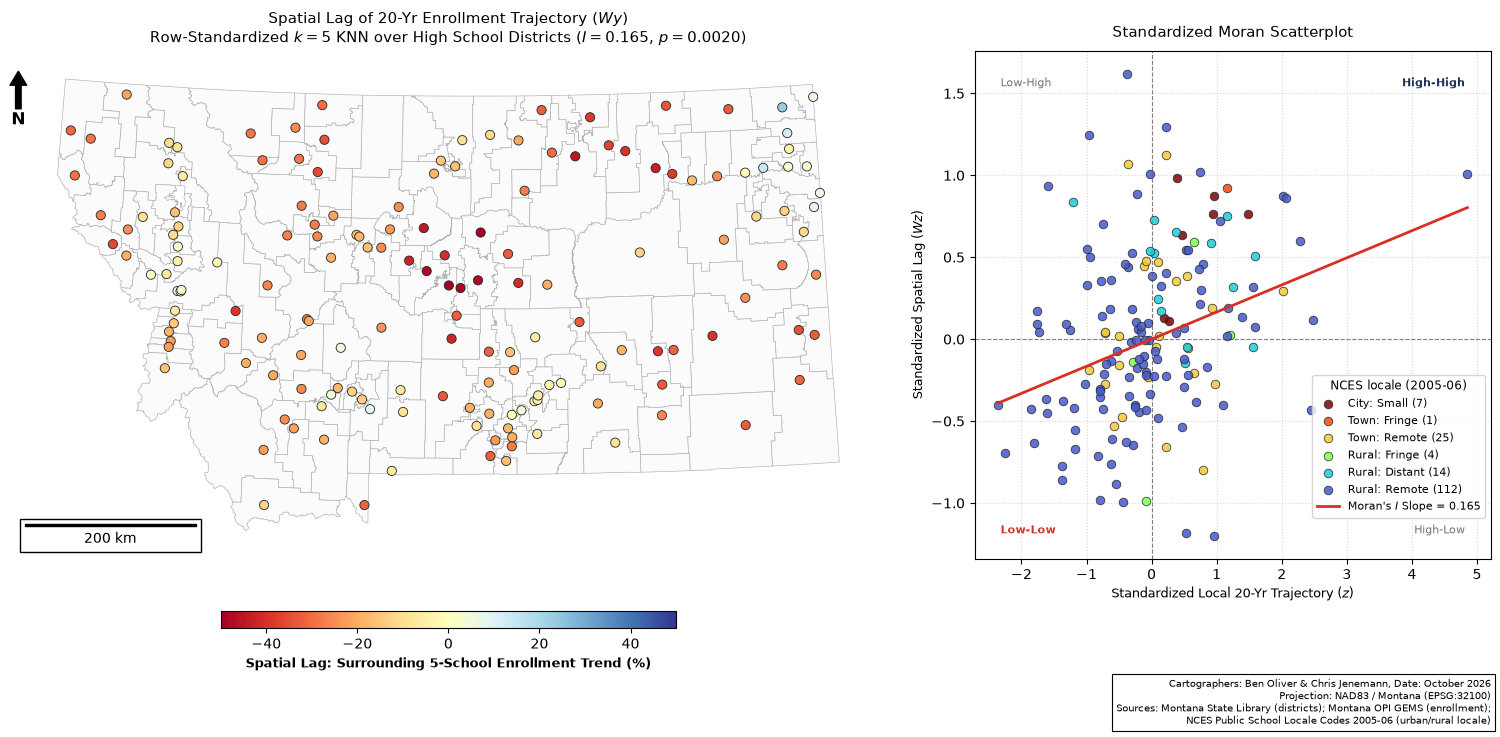

In [3]:
# plot time!
fig = plt.figure(figsize=(19, 7.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 0.75], height_ratios=[30, 1], wspace=0.14)

ax_map = fig.add_subplot(gs[0, 0])
ax_moran = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[1, 0].subgridspec(1, 3, width_ratios=[1, 3, 1])[1])

# fig 1 spatial lag map
gdf_districts.plot(ax=ax_map, color='#fbfbfb', edgecolor='#b0b0b0', linewidth=0.45, zorder=1)

norm = mcolors.TwoSlopeNorm(vmin=-50, vcenter=0, vmax=50)
sc = ax_map.scatter(
    gdf_schools.geometry.x, gdf_schools.geometry.y,
    c=gdf_schools['lag_pct_change'], 
    cmap='RdYlBu', 
    norm=norm,
    s=44, 
    edgecolor='#212529', 
    linewidth=0.6, 
    zorder=3
)

ax_map.set_title(
    f"Spatial Lag of 20-Yr Enrollment Trajectory ($Wy$)\n"
    f"Row-Standardized $k=5$ KNN over High School Districts ($I = {moran.I:.3f}$, $p = {moran.p_sim:.4f}$)",
    fontsize=11, pad=10
)
ax_map.axis('off')
add_map_furniture(ax_map, north_x=0.0)

cbar = fig.colorbar(sc, cax=cax, orientation='horizontal')
cbar.set_label("Spatial Lag: Surrounding 5-School Enrollment Trend (%)", fontsize=9, fontweight='bold')

# fig 2 moran scatterplot
# points colored by nces locale, ordered urban -> remote; schools opened after 2005-06 have no code
locale_names = {
    '11': 'City: Large', '12': 'City: Midsize', '13': 'City: Small',
    '21': 'Suburb: Large', '22': 'Suburb: Midsize', '23': 'Suburb: Small',
    '31': 'Town: Fringe', '32': 'Town: Distant', '33': 'Town: Remote',
    '41': 'Rural: Fringe', '42': 'Rural: Distant', '43': 'Rural: Remote',
}
codes = sorted(gdf_schools['ulocale'].dropna().unique())
locale_styles = {c: (color, locale_names[c]) for c, color in zip(codes, plt.cm.turbo_r(np.linspace(0, 0.9, len(codes))))}
locale_styles[None] = ('#cfcfcf', 'Not classified (opened after 2005-06)')
for code, (color, label) in locale_styles.items():
    m = (gdf_schools['ulocale'].isna() if code is None else gdf_schools['ulocale'] == code).to_numpy()
    if not m.any():
        continue
    ax_moran.scatter(y_std[m], lag_std[m], color=color, edgecolor='#212529', linewidth=0.6,
                     alpha=0.85, s=38, zorder=3, label=f"{label} ({m.sum()})")

# render morans i line
x_vals = np.linspace(y_std.min(), y_std.max(), 100)
ax_moran.plot(
    x_vals, moran.I * x_vals, 
    color='#d73027', 
    linewidth=2.0, 
    label=f"Moran's $I$ Slope = {moran.I:.3f}", 
    zorder=4
)

ax_moran.axhline(0, color='grey', linestyle='--', linewidth=0.8)
ax_moran.axvline(0, color='grey', linestyle='--', linewidth=0.8)

# quadrant labels (x = school's own trend, y = its neighbors' trend)
ax_moran.text(0.95, 0.05, "High-Low", transform=ax_moran.transAxes, ha='right', fontsize=8, color='#6c757d')
ax_moran.text(0.05, 0.05, "Low-Low", transform=ax_moran.transAxes, fontsize=8, color='#d73027', fontweight='bold')
ax_moran.text(0.95, 0.93, "High-High", transform=ax_moran.transAxes, ha='right', fontsize=8, color='#1d3557', fontweight='bold')
ax_moran.text(0.05, 0.93, "Low-High", transform=ax_moran.transAxes, fontsize=8, color='#6c757d')

ax_moran.set_title("Standardized Moran Scatterplot", fontsize=11, pad=10)
ax_moran.set_xlabel("Standardized Local 20-Yr Trajectory ($z$)", fontsize=9)
ax_moran.set_ylabel("Standardized Spatial Lag ($Wz$)", fontsize=9)
ax_moran.grid(True, linestyle=':', alpha=0.5)
ax_moran.legend(title="NCES locale (2005-06)", title_fontsize=8.5, frameon=True, fontsize=8, loc='lower right', bbox_to_anchor=(1.0, 0.07))

plt.tight_layout()
add_cartographer_box(fig, gdf_districts.crs, "Montana State Library (districts); Montana OPI GEMS (enrollment);\n"
                     "NCES Public School Locale Codes 2005-06 (urban/rural locale)")
plt.savefig("view3_python_spatial_lag_fixed.png", dpi=300, bbox_inches="tight")
plt.show()

### View 3: Refined spatial lag + Moran scatterplot (NCES locale)
Working: The map now carries a scale bar, north arrow, centered colorbar, projection, and sources. The quadrant labels are corrected. Coloring the scatter by NCES urban/rural locale (2005-06 urban-centric codes) shows whether the declining schools are the remote rural ones. The positive Moran's I slope shows that growing schools sit near growing schools and shrinking near shrinking.

Needs attention:
- Global Moran's I answers *whether* there is clustering, but not *where*. We still can't name the cluster we want to study.
- The map shows each school's neighbors' average (the lag), not its own value. A reader can mistake a stable school surrounded by declining ones for a declining school, which is a fidelity risk.
- Nothing yet speaks to *consequences*. The hypothesis is about what closing these schools would cost students.

Next revision: Bring in a second variable for that cost (distance to the school students would be sent to), and later use local Moran's I (LISA) to pick a study area.

### View 4: Enrollment change vs. isolation (distance to the nearest larger school)
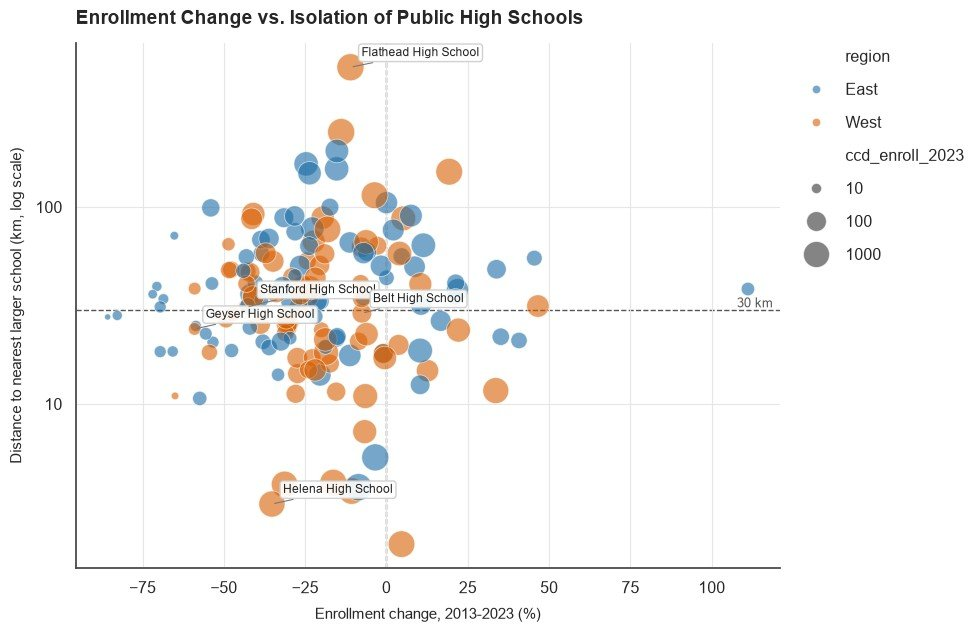

*For each school we found the nearest school with higher 2023 enrollment (the likely consolidation partner) and measured the straight-line distance.*

Working: This adds the second half of the hypothesis: shrinking schools (left) that are also isolated (above the 30 km line) are where consolidation would hurt most. The log y-axis and log-sized bubbles handle the heavy skew in distance and enrollment.

Needs attention:
- It's aspatial: once the data leave the map, the reader can't see *where* these schools are. The East/West split at −110° is an arbitrary zoning choice (a MAUP-style decision) and adds nothing.
- Straight-line distance is not travel cost. Montana roads go around mountains and rivers, so Euclidean km understate real access.
- The size legend has no units, labels collide, and the default orange/blue pair isn't tied to any variable worth encoding.

Next revision: Replace Euclidean distance with network drive time (OSMnx + Dijkstra). Start with Helena as an urban control, where two large schools sit 2 km apart.

---
## Part 2: Urban control: what would closing Helena High cost?

In [4]:
# load district, school, and population data
data = gpd.read_file("MontanaSchoolDistricts_shp/MontanaSchoolDistricts_shp/Secondary.shp")
schools = gpd.read_file("MontanaSchools/MontanaSchools.shp")
population = gpd.read_file("clipped_pop.gpkg")

# filter to helena school district and match crs
data = data.set_index("NAME", drop=False)
helena = data.loc[["HELENA HIGH SCHOOL"]]
schools = schools.to_crs(helena.crs)

# get target schools
schools = schools.set_index("NAME", drop=False)
helena_high = schools.loc[["Helena High School"]]
capital_high = schools.loc[["Capital High School"]]

# montana outline + helper for a location inset (red dot = center of the zoomed map)
mt = pd.concat([data, gpd.read_file("MontanaSchoolDistricts_shp/MontanaSchoolDistricts_shp/Unified.shp")]).pipe(gpd.GeoDataFrame).union_all()
mt = gpd.GeoSeries([mt], crs=helena.crs).simplify(500)

def add_mt_inset(ax, lims_x, lims_y, loc=(0.70, 0.14, 0.28, 0.2)):
    ins = ax.inset_axes(loc)
    mt.plot(ax=ins, color="#dddddd", linewidth=0.6)
    ins.plot(sum(lims_x) / 2, sum(lims_y) / 2, "o", color="red", markersize=3)
    ins.set_xticks([]); ins.set_yticks([])
    ins.set_title("Montana", fontsize=8, pad=2)

# prep population data inside helena district
pop_col = "population"
pop = population.to_crs(helena.crs)
district_geom = helena.union_all()
pop = pop[pop.centroid.within(district_geom)].copy()
pop["geometry"] = pop.geometry.centroid

# get road network from osm and add travel times (cached locally after first download)
graph_path = Path("helena.graphml")
if graph_path.exists():
    G = ox.load_graphml(graph_path)
else:
    G = ox.graph_from_polygon(helena.to_crs(4326).union_all(), network_type="drive")
    G = ox.project_graph(G, to_crs=helena.crs)
    G = ox.routing.add_edge_speeds(G)
    G = ox.routing.add_edge_travel_times(G)
    ox.save_graphml(G, graph_path)

# find nearest network nodes for each school
sources = []
for school in [helena_high, capital_high]:
    x = school.geometry.x.iloc[0]
    y = school.geometry.y.iloc[0]
    sources.append(ox.distance.nearest_nodes(G, x, y))

# compute drive times using reversed graph (routes heading toward school)
G_rev = G.reverse(copy=False)
times = nx.multi_source_dijkstra_path_length(G_rev, sources, weight="travel_time")
times_combined = nx.single_source_dijkstra_path_length(G_rev, sources[1], weight="travel_time")

# map travel times in minutes to network edges
edges = ox.graph_to_gdfs(G, nodes=False)
edges["minutes"] = [times.get(u, float("nan")) / 60 for u in edges.index.get_level_values("u")]
edges["minutes_combined"] = [times_combined.get(u, float("nan")) / 60 for u in edges.index.get_level_values("u")]
edges["delta_minutes"] = (edges["minutes_combined"] - edges["minutes"]).clip(lower=0)

# calculate zoom bounds around urban helena and affected streets
b_edges = edges[edges["delta_minutes"] > 0].total_bounds
b_h = helena_high.total_bounds
b_c = capital_high.total_bounds

minx = min(b_edges[0], b_h[0], b_c[0])
miny = min(b_edges[1], b_h[1], b_c[1])
maxx = max(b_edges[2], b_h[2], b_c[2])
maxy = max(b_edges[3], b_h[3], b_c[3])

pad_x = (maxx - minx) * 0.30
pad_y = (maxy - miny) * 0.30

x_lims = (minx - pad_x, maxx + pad_x)
y_lims = (miny - pad_y, maxy + pad_y)

# filter edges in zoom area to scale colormap strictly to local urban drive times
edges_zoomed = edges.cx[x_lims[0]:x_lims[1], y_lims[0]:y_lims[1]]
max_minutes = max(
    edges_zoomed["minutes"].dropna().quantile(0.98),
    edges_zoomed["minutes_combined"].dropna().quantile(0.98)
)

### View 5: First drive-time map, Helena district
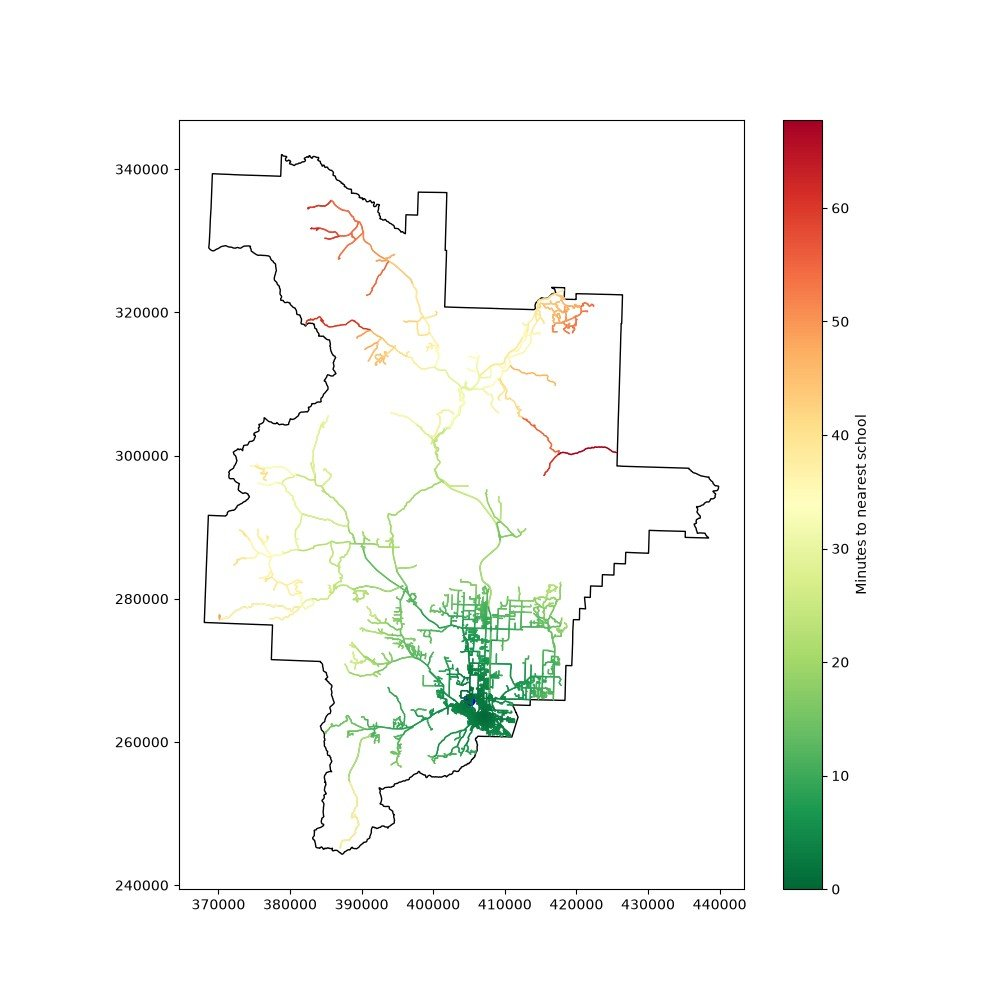

Working: The pipeline works. We downloaded the OSM drive network for the district polygon, added speeds and travel times, and ran multi-source Dijkstra on the reversed graph so times run *toward* a school.

Needs attention:
- The axes show raw projected coordinates (non-data ink, meaningless to a reader). There's no title, the schools are invisible, and the CRS isn't stated.
- `RdYlGn` is red–green (not colorblind-safe) and *diverging*, but drive time has no meaningful midpoint, so it needs a sequential scheme.
- Only one scenario is shown, with nothing to compare against. Every road segment counts equally whether 2 or 2,000 people live along it.

Next revision: Show before/after side by side on a shared scale, mark the schools, and drop the axes.

### View 6: Before/after small multiples, full district extent
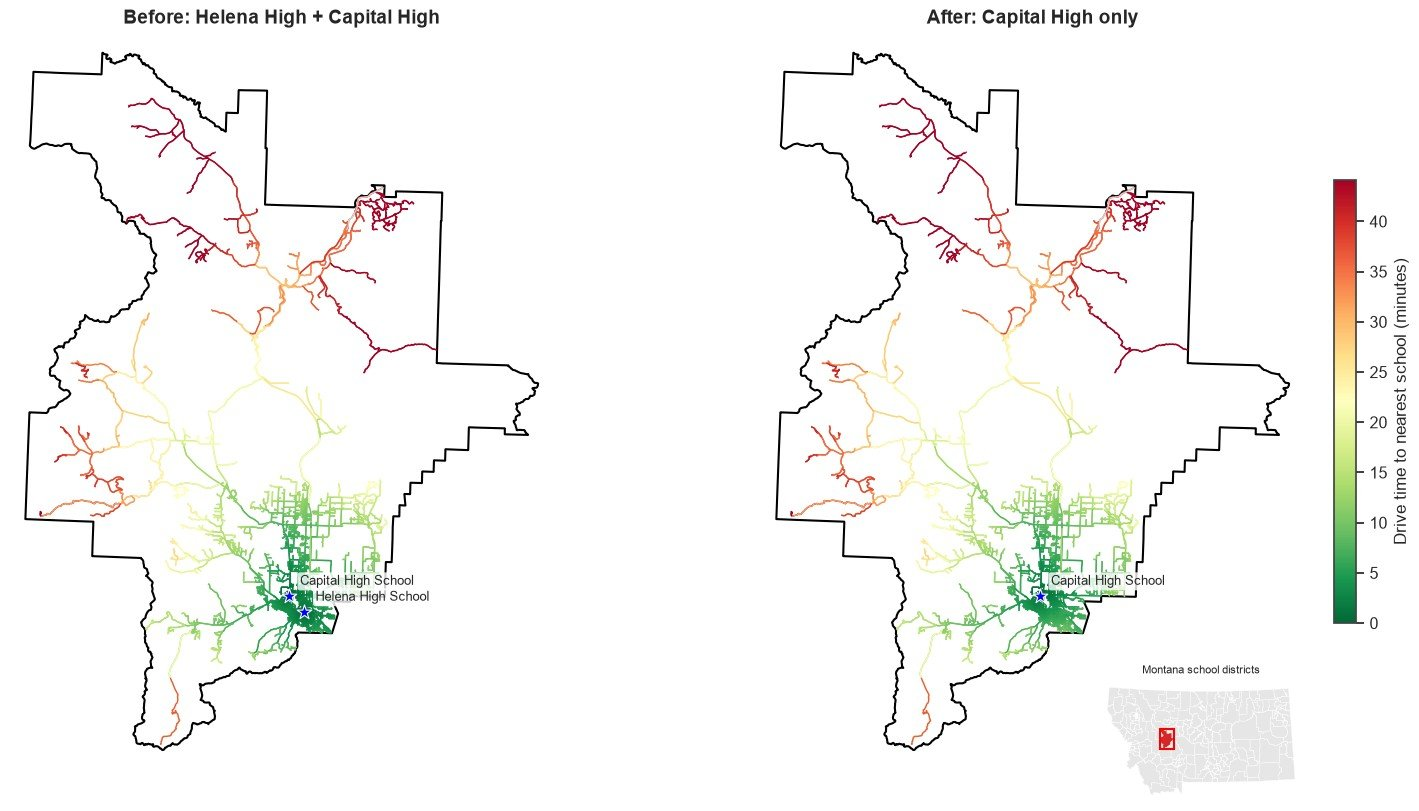

Working: Small multiples with one shared colorbar make the two scenarios directly comparable, and the Montana inset gives location context.

Needs attention:
- The two panels look identical. Every change happens in a few square km of downtown, and at full-district extent it's invisible. The display hides the one thing it exists to show.
- The scheme is still `RdYlGn`. The star markers and labels overlap, and there's still no scale bar, north arrow, or sources.

Next revision: Zoom to the affected streets, switch to sequential `YlOrRd` scaled to local drive times, and add full map furniture.

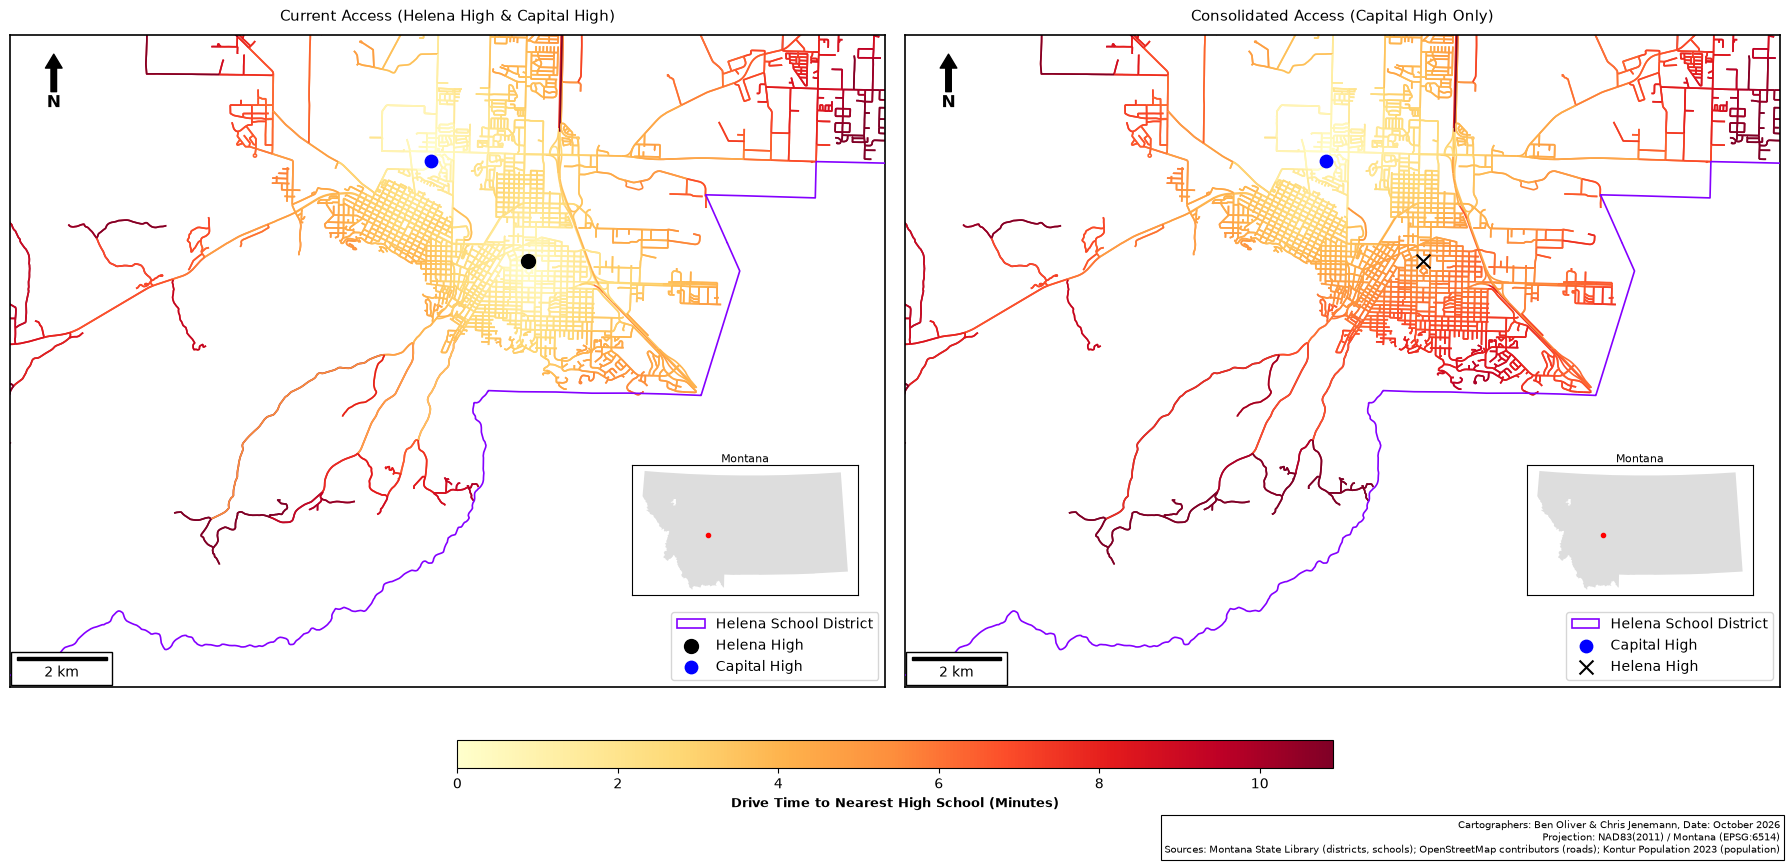

In [5]:
# plot side-by-side drive times
fig = plt.figure(figsize=(18, 9))
gs = fig.add_gridspec(2, 4, height_ratios=[30, 1])
ax1 = fig.add_subplot(gs[0, :2])
ax2 = fig.add_subplot(gs[0, 2:], sharey=ax1)
cax = fig.add_subplot(gs[1, 1:3])

# current scenario (both schools)
edges.plot(column="minutes", cmap="YlOrRd", vmin=0, vmax=max_minutes, linewidth=1.2, ax=ax1)
helena.plot(ax=ax1, facecolor="none", edgecolor="#8400FF", linewidth=1.2, label="Helena School District", zorder=4)
helena_high.plot(ax=ax1, color="#000", markersize=100, label="Helena High", zorder=5)
capital_high.plot(ax=ax1, color="blue", markersize=80, label="Capital High", zorder=5)
ax1.set_xlim(x_lims)
ax1.set_ylim(y_lims)
ax1.set_title("Current Access (Helena High & Capital High)", fontsize=11, pad=10)
ax1.legend(loc="lower right", frameon=True)

# combined scenario (capital high only)
p2 = edges.plot(column="minutes_combined", cmap="YlOrRd", vmin=0, vmax=max_minutes, linewidth=1.2, ax=ax2)
helena.plot(ax=ax2, facecolor="none", edgecolor="#8400FF", linewidth=1.2, label="Helena School District", zorder=4)
capital_high.plot(ax=ax2, color="blue", markersize=80, label="Capital High", zorder=5)
helena_high.plot(ax=ax2, marker="x", color="#000", markersize=100, label="Helena High", zorder=5)
ax2.set_xlim(x_lims)
ax2.set_ylim(y_lims)
ax2.set_title("Consolidated Access (Capital High Only)", fontsize=11, pad=10)
ax2.legend(loc="lower right", frameon=True)
add_mt_inset(ax1, x_lims, y_lims)
add_mt_inset(ax2, x_lims, y_lims)

# shared colorbar scaled to urban drive times
cbar = fig.colorbar(p2.collections[0], cax=cax, orientation="horizontal")
cbar.set_label("Drive Time to Nearest High School (Minutes)", fontsize=9, fontweight="bold")
for ax in [ax1, ax2]:
    add_map_furniture(ax)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)
plt.tight_layout()
add_cartographer_box(fig, helena.crs, "Montana State Library (districts, schools); OpenStreetMap contributors (roads); Kontur Population 2023 (population)")
plt.show()

### View 7: Zoomed before/after, sequential scale
Working: The zoom extent is computed from the edges whose drive time actually changes. `YlOrRd` is sequential and colorblind-friendly, and its maximum is the 98th percentile of the zoomed edges, so the urban gradient isn't washed out by a few remote roads. The closed school is an X and the open school a dot. Scale bar, north arrow, inset, and sources are on every panel.

Needs attention:
- The reader still has to diff two maps by eye to find the change. The subtraction should be done for them.
- Capping the scale at the 98th percentile saturates the outer roads. That's honest only if we say so (the label says "minutes", not "≥ 11 min").
- The inset and legend are duplicated across panels (redundant ink), and roads are still not weighted by how many people use them.

Next revision: Map the difference directly, grey out unaffected roads, and summarize with population-weighted statistics.

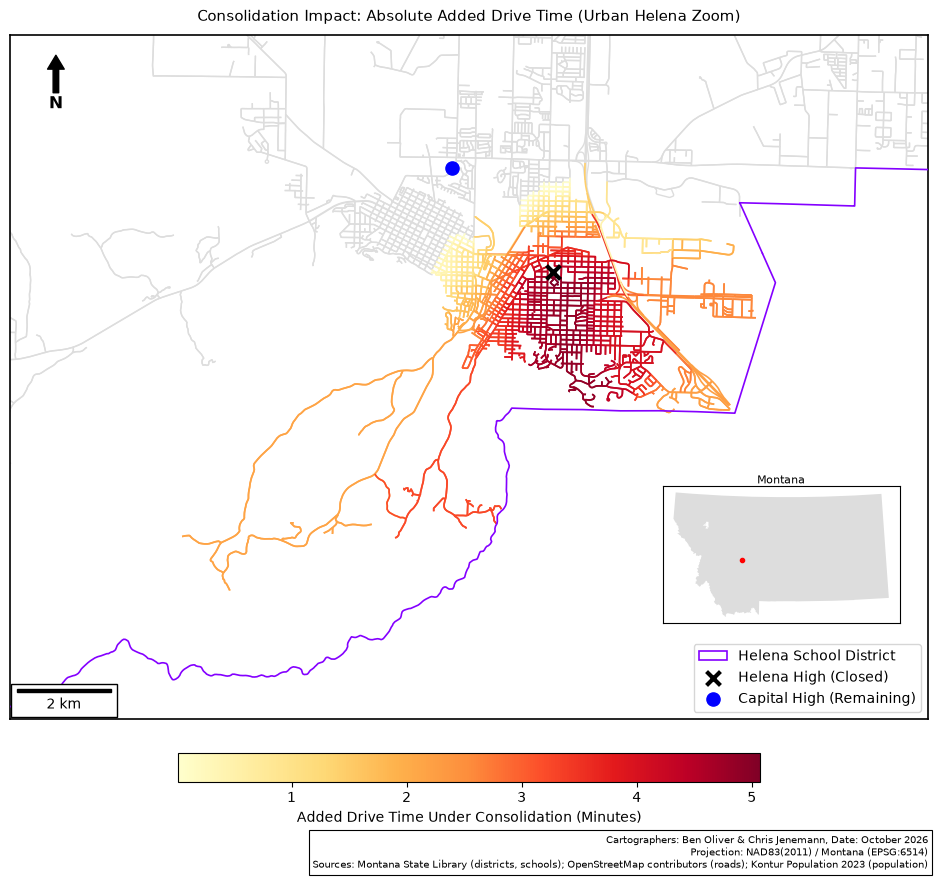

In [6]:
# plot delta map showing added minutes (zoomed)
fig, ax_delta = plt.subplots(figsize=(10, 9))

# plot unaffected roads in light grey
edges[edges["delta_minutes"] == 0].plot(ax=ax_delta, color="#dddddd", linewidth=1.0, zorder=1)

# plot edges with added drive time on top
p_delta = edges[edges["delta_minutes"] > 0].plot(
    column="delta_minutes",
    cmap="YlOrRd",
    linewidth=1.2,
    legend=True,
    legend_kwds={"label": "Added Drive Time Under Consolidation (Minutes)", "orientation": "horizontal", "shrink": 0.6, "pad": 0.04},
    ax=ax_delta,
    zorder=2
)

helena.plot(ax=ax_delta, facecolor="none", edgecolor="#8400FF", linewidth=1.2, zorder=3, label="Helena School District")
helena_high.plot(ax=ax_delta, color="#000", marker="x", markersize=100, linewidth=3.0, label="Helena High (Closed)", zorder=5)
capital_high.plot(ax=ax_delta, color="blue", markersize=90, label="Capital High (Remaining)", zorder=5)

ax_delta.set_xlim(x_lims)
ax_delta.set_ylim(y_lims)
ax_delta.set_title("Consolidation Impact: Absolute Added Drive Time (Urban Helena Zoom)", fontsize=11, pad=10)
ax_delta.legend(loc="lower right", frameon=True)
add_mt_inset(ax_delta, x_lims, y_lims)
add_map_furniture(ax_delta)
ax_delta.set_xticks([])
ax_delta.set_yticks([])
for spine in ax_delta.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)
plt.tight_layout()
add_cartographer_box(fig, helena.crs, "Montana State Library (districts, schools); OpenStreetMap contributors (roads); Kontur Population 2023 (population)")
plt.show()

In [7]:
# snap pop points to network and calculate drive times
pop["node"] = ox.distance.nearest_nodes(G, pop.geometry.x.values, pop.geometry.y.values)
pop["minutes"] = pop["node"].map(times) / 60
pop["minutes_combined"] = pop["node"].map(times_combined) / 60
pop["delta_minutes"] = (pop["minutes_combined"] - pop["minutes"]).clip(lower=0)
pop = pop.dropna(subset=["minutes", "minutes_combined"]).copy()

# weighted stats helper
w = pop[pop_col]

def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v = np.asarray(values)[order]
    weights_ordered = np.asarray(weights)[order]
    cum = np.cumsum(weights_ordered) / weights_ordered.sum()
    return np.interp(q, cum, v)

def calc_stats(col):
    return {
        "Population-weighted mean": np.average(pop[col], weights=w),
        "Population-weighted median": weighted_quantile(pop[col], w, 0.5),
        "90th percentile": weighted_quantile(pop[col], w, 0.9),
        "Share within 10 min (%)": (w[pop[col] <= 10].sum() / w.sum()) * 100,
    }

# summary dataframe
driving_dataframe = pd.DataFrame([
    {"Scenario": "Current", **calc_stats("minutes")},
    {"Scenario": "Combined", **calc_stats("minutes_combined")},
])

print(driving_dataframe.to_string(index=False))

mean_curr = driving_dataframe.loc[0, "Population-weighted mean"]
mean_comb = driving_dataframe.loc[1, "Population-weighted mean"]
diff_mean = mean_comb - mean_curr
pct_mean = (diff_mean / mean_curr) * 100

# stats specifically for people who saw an increase
affected_pop = pop[pop["delta_minutes"] > 0.1]
w_aff = affected_pop[pop_col]
avg_added = np.average(affected_pop["delta_minutes"], weights=w_aff)

print(f"\nMean Change Across District: +{diff_mean:.2f} minutes (+{pct_mean:.1f}%)")
print(f"Mean Added Drive Time for Affected Students: +{avg_added:.2f} minutes")

# keep the helena numbers for the final view (pop/times get reused by the rural case)
helena_summary = driving_dataframe.copy()

Scenario  Population-weighted mean  Population-weighted median  90th percentile  Share within 10 min (%)
 Current                  6.098999                    3.829776        12.271752                80.854532
Combined                  7.354981                    6.248986        12.356896                80.484326

Mean Change Across District: +1.26 minutes (+20.6%)
Mean Added Drive Time for Affected Students: +3.31 minutes


### View 8: Added drive time + population-weighted statistics
Working: One delta map replaces two, and unaffected roads drop to light grey (figure-ground), so the affected area pops out. We overlaid Kontur population hexagons on the district (clipped by centroid-within), snapped each hex to its nearest network node, and weighted the drive times by population. Closing Helena High raises the population-weighted mean drive time by +1.26 min (+21%). Affected residents average +3.3 min, and the share within 10 minutes barely moves (80.9% $\to$ 80.5%). In a city, consolidation is cheap.

Needs attention:
- Helena is a control, not the case our hypothesis is about. The claim concerns rural schools, and we haven't measured one yet.
- The key numbers live in printed text, not on a graphic.

Next revision: Pick a rural study area using evidence (LISA), not intuition. An earlier draft tried Geyser/Belt/Stanford by eye. Then rerun the same pipeline there.

---
## Part 3: Choosing the rural case with local Moran's I (LISA)
Global Moran's I said decline is clustered; LISA tells us where. Each school gets a local statistic and a conditional-permutation pseudo p-value (9,999 permutations). A significant Low-Low school is shrinking *and* surrounded by shrinking schools: a cold spot.

In [8]:
# local moran's i (lisa): which schools sit in statistically significant clusters?
lisa = Moran_Local(gdf_schools['pct_change_20yr'], w_knn5, permutations=9999, seed=42)
quad_names = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
gdf_schools['lisa'] = np.where(lisa.p_sim < 0.05, pd.Series(lisa.q).map(quad_names), "Not significant")
gdf_schools['lisa_p'] = lisa.p_sim

print(gdf_schools['lisa'].value_counts().to_string(), "\n")
cols = ['SCHOOL_NAME', 'COUNTY', 'ccd_enroll_2023', 'pct_change_20yr', 'lisa', 'lisa_p']
print("Significant Low-Low (cold spot) schools:")
print(gdf_schools.loc[gdf_schools['lisa'] == 'Low-Low', cols].sort_values('pct_change_20yr').round(3).to_string(index=False))
print("\nOur rural case-study schools:")
case = gdf_schools['SCHOOL_NAME'].isin([f"{n} High School" for n in ["Denton", "Stanford", "Geraldine", "Hobson"]])
print(gdf_schools.loc[case, cols].round(3).to_string(index=False))

lisa
Not significant    132
High-High           12
Low-Low              9
Low-High             7
High-Low             3 

Significant Low-Low (cold spot) schools:
            SCHOOL_NAME       COUNTY  ccd_enroll_2023  pct_change_20yr    lisa  lisa_p
     Denton High School       Fergus             10.0          -82.759 Low-Low   0.040
  Geraldine High School     Chouteau             16.0          -58.974 Low-Low   0.015
     Geyser High School Judith Basin             16.0          -58.974 Low-Low   0.027
Grass Range High School       Fergus             28.0          -44.000 Low-Low   0.038
   Stanford High School Judith Basin             33.0          -43.103 Low-Low   0.007
  Harlowton High School    Wheatland             70.0          -38.596 Low-Low   0.032
      Malta High School     Phillips            122.0          -36.126 Low-Low   0.015
      Moore High School       Fergus             18.0          -33.333 Low-Low   0.006
     Fergus High School       Fergus            355.0 

Result: The significant Low-Low cold spot is centered on Fergus and Judith Basin counties in central Montana (with outliers in Chouteau, Wheatland, and Phillips). Denton, Stanford, and Geraldine are all significant Low-Low schools, and adjacent Hobson is a significant High-Low outlier (stable while its neighbors shrink). That makes these four adjacent districts an evidence-based rural case. In practice, a consolidation would most plausibly send students to the school that is holding steady.

The cells below rerun the Helena pipeline on these four districts under five scenarios: the current state, and "all students into X" for each of the four schools.

In [9]:
# load district, school, and population data
data_unified = gpd.read_file("MontanaSchoolDistricts_shp/MontanaSchoolDistricts_shp/Unified.shp").set_index("NAME", drop=False)
data_secondary = gpd.read_file("MontanaSchoolDistricts_shp/MontanaSchoolDistricts_shp/Secondary.shp").set_index("NAME", drop=False)
schools = gpd.read_file("MontanaSchools/MontanaSchools.shp")
population = gpd.read_file("clipped_population_Denton_area.gpkg")

# filter to the four districts and combine into one frame
combined = gpd.GeoDataFrame(pd.concat([
    data_secondary.loc[["DENTON HIGH SCHOOL"]],
    data_unified.loc[["STANFORD K-12 SCHOOLS", "GERALDINE K-12", "HOBSON K-12 SCHOOLS"]],
], ignore_index=True))

# get target schools
schools = schools.to_crs(combined.crs).set_index("NAME", drop=False)
hs = {n: schools.loc[[f"{n} High School"]] for n in ["Denton", "Stanford", "Geraldine", "Hobson"]}

# prep population data inside the districts (population is already a count per hexagon)
pop_col = "population"
pop = population.to_crs(combined.crs)
pop = pop[pop.centroid.within(combined.union_all())].copy()
pop["geometry"] = pop.geometry.centroid

In [10]:
# run once to download the road network from osm; the cached copy is loaded in the next cell
# # get road network from osm and add travel times
# G = ox.graph_from_polygon(combined.to_crs(4326).union_all(), network_type="drive")
# G = ox.project_graph(G, to_crs=combined.crs)
# G = ox.routing.add_edge_speeds(G)
# G = ox.routing.add_edge_travel_times(G)
# ox.save_graphml(G, "denton_area.graphml")

In [11]:
G = ox.load_graphml("denton_area.graphml")

In [12]:
# scenarios: which high schools stay open (edit this to try other consolidations)
scenarios = {"Current": list(hs)} | {f"All into {n}": [n] for n in hs}

# find nearest network nodes for each school
nodes = {n: ox.distance.nearest_nodes(G, s.geometry.x.iloc[0], s.geometry.y.iloc[0]) for n, s in hs.items()}

# compute drive times using reversed graph (routes heading toward school)
G_rev = G.reverse(copy=False)
times = {
    sc: nx.multi_source_dijkstra_path_length(G_rev, [nodes[n] for n in open_], weight="travel_time")
    for sc, open_ in scenarios.items()
}

# map travel times in minutes to network edges, plus added minutes vs. current
edges = ox.graph_to_gdfs(G, nodes=False)
u = edges.index.get_level_values("u")
for sc, t in times.items():
    edges[sc] = [t.get(n, float("nan")) / 60 for n in u]
for sc in list(scenarios)[1:]:
    edges[f"delta {sc}"] = (edges[sc] - edges["Current"]).clip(lower=0)

# zoom bounds around the districts, and a colormap max from the 98th percentile
minx, miny, maxx, maxy = combined.total_bounds
pad_x, pad_y = (maxx - minx) * 0.05, (maxy - miny) * 0.05
x_lims = (minx - pad_x, maxx + pad_x)
y_lims = (miny - pad_y, maxy + pad_y)
max_minutes = max(edges[sc].dropna().quantile(0.98) for sc in scenarios)

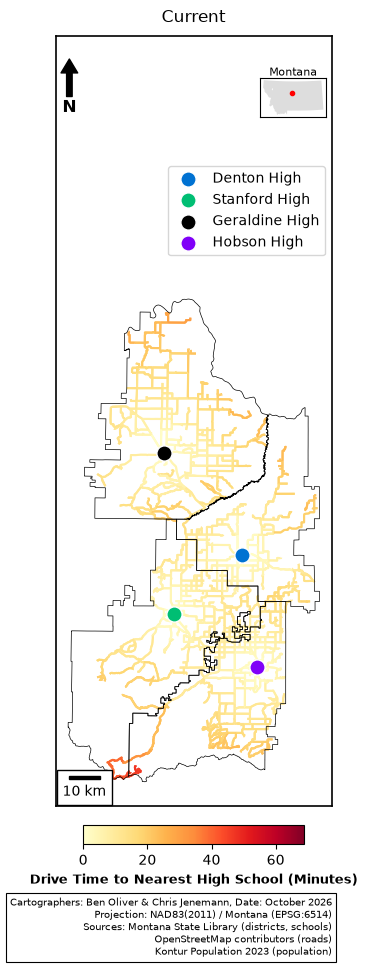

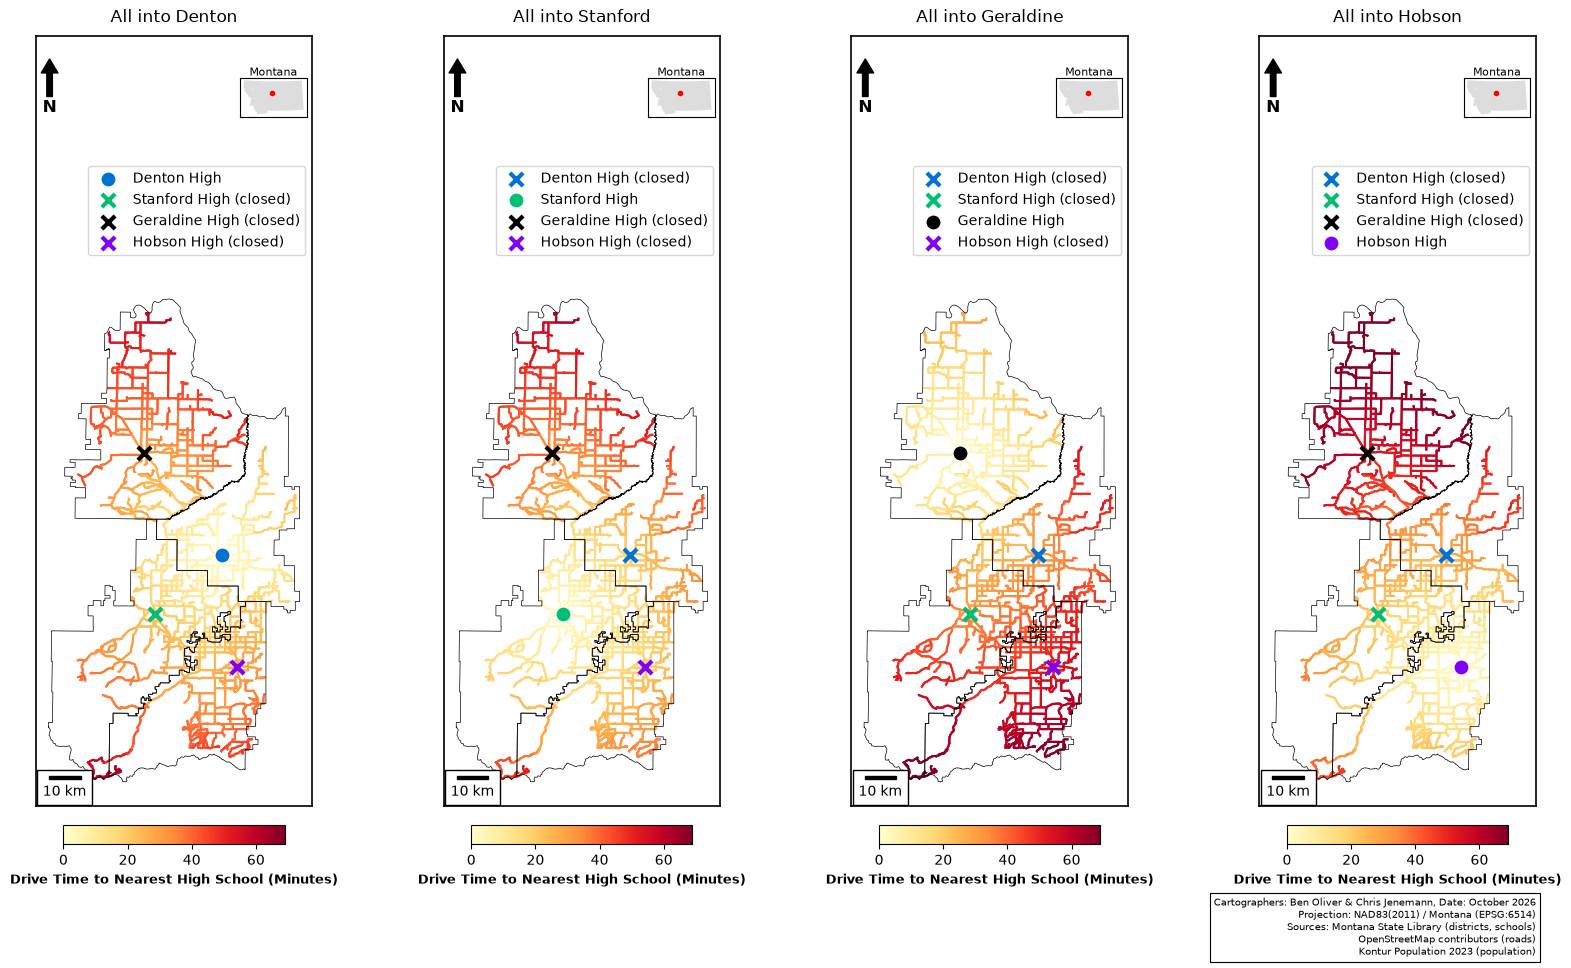

In [13]:
# one color per school (kept clear of the yellow-red roads)
school_colors = {"Denton": "#0072d2", "Stanford": "#00bE73", "Geraldine": "#000000", "Hobson": "#8000F8"}

# shared helper: draws one scenario map onto ax, fixed color scale
def draw_map(ax, col, title, open_, vmax, cmap, cbar_label, mask=None):
    fig = ax.figure
    if mask is not None:  # unaffected roads in light grey underneath
        edges[~mask].plot(ax=ax, color="#dddddd", linewidth=1.0, zorder=1)
    (edges if mask is None else edges[mask]).plot(
        column=col, cmap=cmap, vmin=0, vmax=vmax, linewidth=1.5, ax=ax, zorder=2)
    combined.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.5, zorder=3)
    for n, s in hs.items():
        if n in open_:
            s.plot(ax=ax, color=school_colors[n], markersize=120, edgecolor="white", linewidth=1,
                   label=f"{n} High", zorder=5)
        else:
            s.plot(ax=ax, color=school_colors[n], marker="x", markersize=90, linewidth=3,
                   label=f"{n} High (closed)", zorder=5)
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.84), frameon=True, fontsize=10)
    ax.set_xlim(x_lims)
    ax.set_ylim(y_lims[0], y_lims[1] + 0.45 * (y_lims[1] - y_lims[0]))  # headroom above the map for inset + legend
    ax.set_title(title, fontsize=12, pad=10)
    add_mt_inset(ax, x_lims, y_lims, loc=(0.74, 0.85, 0.24, 0.14))
    add_map_furniture(ax)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(1.2)

    # colorbar as an inset so it matches the map width
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(0, vmax))
    cax = ax.inset_axes([0.1, -0.05, 0.8, 0.025])  # [x, y, width, height] in axes coords
    cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cbar.set_label(cbar_label, fontsize=9, fontweight="bold")

# current standalone, then the "all into x" scenarios side by side
def draw_all(vmax_, cbar_label, col_fmt="{}", masks=False):
    names = list(scenarios)
    for group in ([names[0]], names[1:]):
        if not group or (masks and group == names[:1]):
            continue
        fig, axes = plt.subplots(1, len(group), figsize=(8 if len(group) == 1 else 5.2 * len(group), 10),
                                 squeeze=False, gridspec_kw={"wspace": 0.05})
        for ax, sc in zip(axes[0], group):
            col = col_fmt.format(sc)
            draw_map(ax, col, sc, scenarios[sc], vmax_, "YlOrRd", cbar_label,
                     mask=edges[col] > 0 if masks else None)
        add_cartographer_box(fig, combined.crs, "Montana State Library (districts, schools)\n OpenStreetMap contributors (roads)\n Kontur Population 2023 (population)")
        plt.show()

# drive time to nearest open high school, same scale for every scenario
draw_all(max_minutes, "Drive Time to Nearest High School (Minutes)")

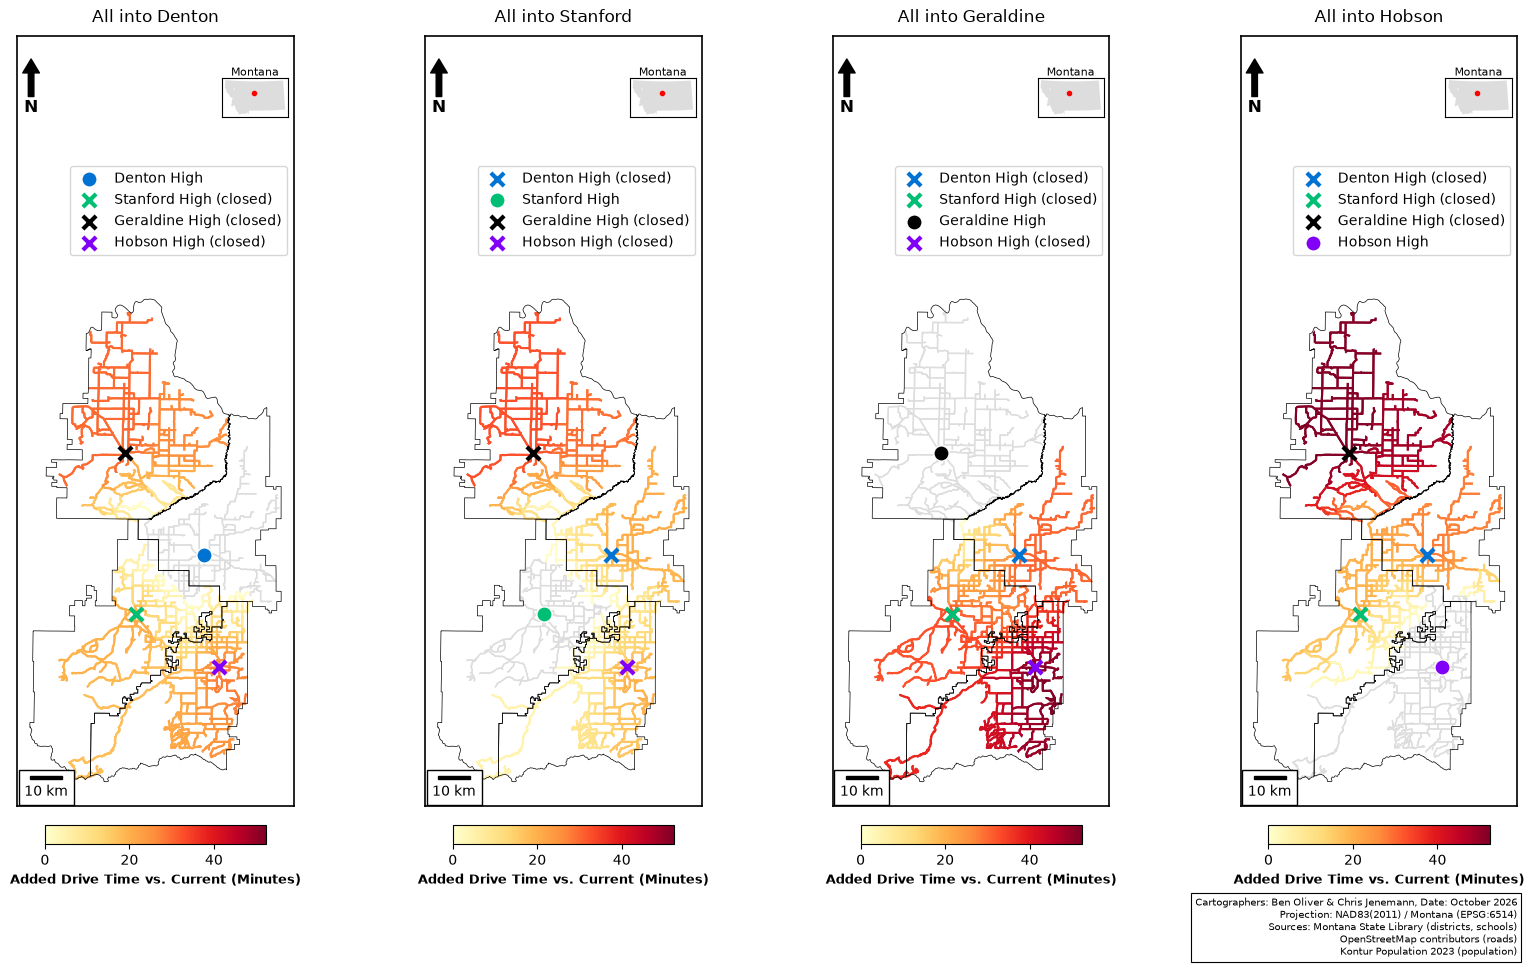

In [14]:
# added minutes vs. current, same scale for every scenario
max_delta = max(edges[f"delta {sc}"].dropna().quantile(0.98) for sc in list(scenarios)[1:])
draw_all(max_delta, "Added Drive Time vs. Current (Minutes)", col_fmt="delta {}", masks=True)

In [15]:
# snap pop points to network and calculate drive times
pop["node"] = ox.distance.nearest_nodes(G, pop.geometry.x.values, pop.geometry.y.values)
for sc, t in times.items():
    pop[sc] = pop["node"].map(t) / 60
pop = pop.dropna(subset=list(scenarios)).copy()

# weights for calc_stats (helpers defined in the helena cell)
w = pop[pop_col]

# summary dataframe
driving_dataframe = pd.DataFrame([{"Scenario": sc, **calc_stats(sc)} for sc in scenarios])
print(driving_dataframe.to_string(index=False))


rural_summary = driving_dataframe.copy()

          Scenario  Population-weighted mean  Population-weighted median  90th percentile  Share within 10 min (%)
           Current                  8.322488                    7.505014        18.226845                64.333132
   All into Denton                 24.334243                   24.390386        40.516061                15.912291
 All into Stanford                 23.257650                   20.882311        42.020839                19.030376
All into Geraldine                 34.088786                   34.180823        53.651008                12.210823
   All into Hobson                 29.566613                   25.685879        60.428363                17.179642


### View 9: Rural drive-time small multiples (Denton / Stanford / Geraldine / Hobson)
Working: The study area comes from the LISA cold spot. Every scenario uses the same color scale, so the small multiples compare honestly (no per-panel rescaling). Closed schools are X's and the school that stays open is a dot, each school keeping its own color across panels. The delta maps grey out unaffected roads. The table shows the scale of the problem: today 64% of residents live within 10 minutes of a high school, and under any single-school scenario only 12–19% do.

Needs attention:
- The "Current" map is a separate figure with a different size, so it doesn't line up with the four scenario panels.
- The legend, inset, and colorbar repeat four times, and the headroom above each map is mostly empty (low data-ink ratio).
- The punchline (rural consolidation adds ~15–26 minutes vs. ~1 minute in Helena) is only in a printed table. Nothing puts the urban and rural results on the same axis, and nothing links the rural case back to the statewide cluster.

---
## Final View

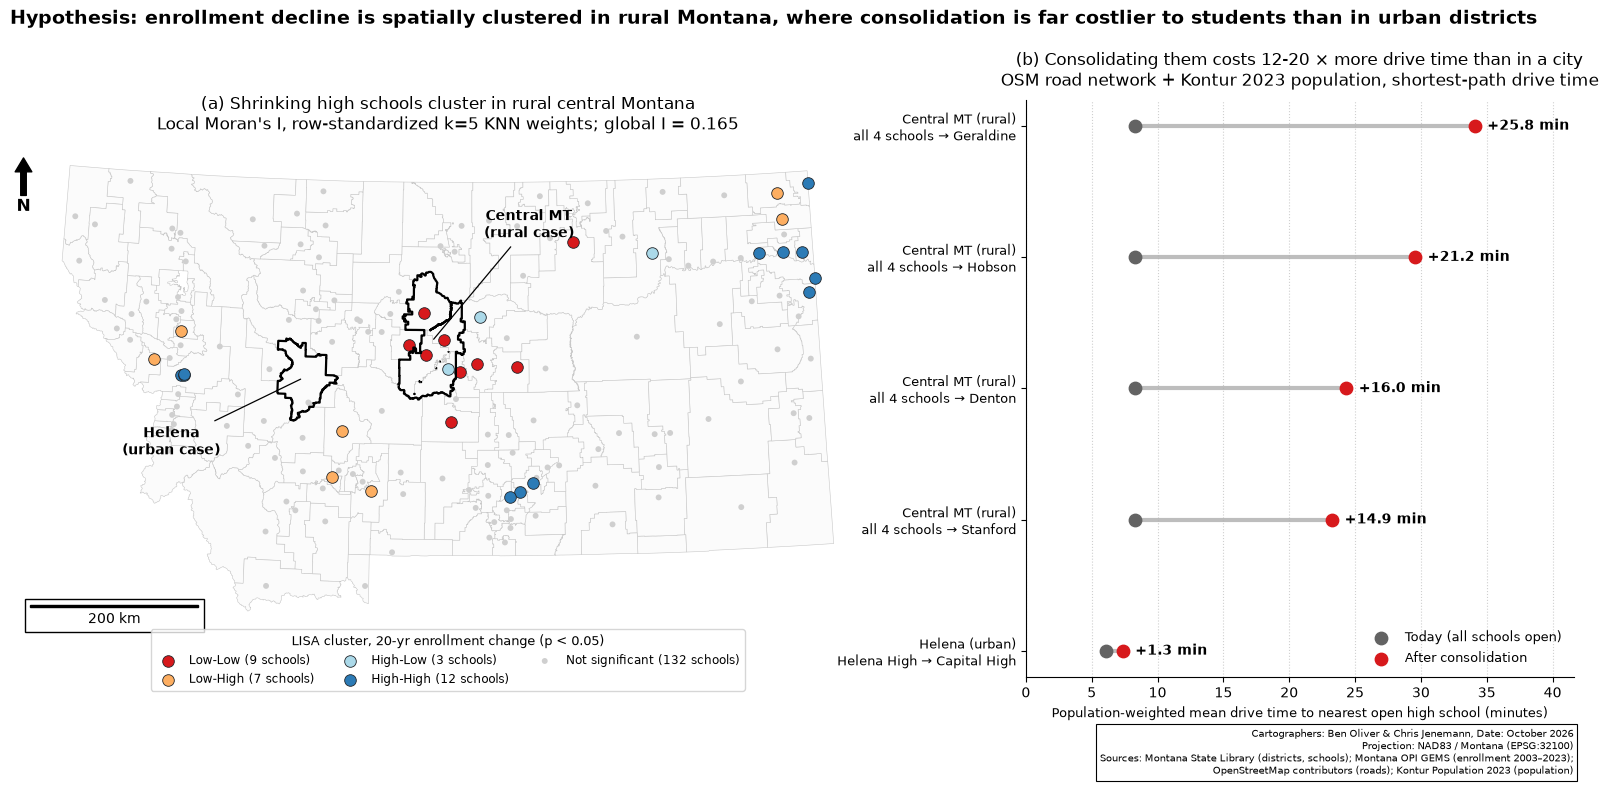

In [18]:
# final view: (a) where enrollment decline clusters (lisa), (b) what consolidation would cost residents in drive time
lisa_colors = {"Low-Low": "#d7191c", "Low-High": "#fdae61", "High-Low": "#abd9e9",
               "High-High": "#2c7bb6", "Not significant": "#cfcfcf"}

fig = plt.figure(figsize=(20, 7.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1], wspace=0.22)
ax_map = fig.add_subplot(gs[0])
ax_cost = fig.add_subplot(gs[1])

# (a) lisa cluster map: significant schools drawn large and outlined, non-significant ones small and grey (figure-ground)
gdf_districts.plot(ax=ax_map, color='#fbfbfb', edgecolor='#c8c8c8', linewidth=0.4, zorder=1)
for lab, color in lisa_colors.items():
    sub = gdf_schools[gdf_schools['lisa'] == lab]
    sig = lab != "Not significant"
    ax_map.scatter(sub.geometry.x, sub.geometry.y, color=color, s=70 if sig else 18,
                   edgecolor='#212529' if sig else 'none', linewidth=0.6, zorder=3 if sig else 2,
                   label=f"{lab} ({len(sub)} schools)")

# outline and label the two case-study areas so the statewide map links to panel (b)
for area, label, offset in [(helena, "Helena\n(urban case)", (-95, -55)), (combined, "Central MT\n(rural case)", (70, 75))]:
    a = area.to_crs(gdf_districts.crs).dissolve()
    a.boundary.plot(ax=ax_map, color='black', linewidth=1.6, zorder=4)
    c = a.geometry.iloc[0].centroid
    ax_map.annotate(label, xy=(c.x, c.y), xytext=offset, textcoords='offset points', fontsize=10, fontweight='bold',
                    ha='center', arrowprops=dict(arrowstyle='-', color='black', lw=0.9))

ax_map.legend(title="LISA cluster, 20-yr enrollment change (p < 0.05)", loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=3,
              fontsize=8.5, title_fontsize=9, frameon=True)  # below the map so it hides no schools
ax_map.set_title("(a) Shrinking high schools cluster in rural central Montana\n"
                 f"Local Moran's I, row-standardized k=5 KNN weights; global I = {moran.I:.3f}",
                 fontsize=12, pad=10)
ax_map.axis('off')
add_map_furniture(ax_map, north_x=0.0)

# (b) dumbbell plot: population-weighted mean drive time today vs. after each consolidation
def pick(df, sc):
    return df.set_index("Scenario").loc[sc, "Population-weighted mean"]

cost = pd.DataFrame(
    [{"label": "Helena (urban)\nHelena High \u2192 Capital High", "before": pick(helena_summary, "Current"),
      "after": pick(helena_summary, "Combined")}]
    + [{"label": f"Central MT (rural)\nall 4 schools \u2192 {sc.split()[-1]}", "before": pick(rural_summary, "Current"),
        "after": pick(rural_summary, sc)} for sc in list(scenarios)[1:]]
).sort_values("after").reset_index(drop=True)

y = np.arange(len(cost))
ax_cost.hlines(y, cost["before"], cost["after"], color='#bdbdbd', linewidth=3, zorder=1)
ax_cost.scatter(cost["before"], y, color='#636363', s=80, zorder=2, label="Today (all schools open)")
ax_cost.scatter(cost["after"], y, color='#d7191c', s=80, zorder=3, label="After consolidation")
for yi, r in cost.iterrows():
    ax_cost.annotate(f"+{r['after'] - r['before']:.1f} min", (r['after'], yi), xytext=(9, 0),
                     textcoords='offset points', va='center', fontsize=10, fontweight='bold')
ax_cost.set_yticks(y, cost["label"], fontsize=9.5)
ax_cost.set_xlim(0, cost["after"].max() * 1.22)
ax_cost.set_xlabel("Population-weighted mean drive time to nearest open high school (minutes)", fontsize=9.5)
ax_cost.spines[['top', 'right']].set_visible(False)
ax_cost.grid(axis='x', linestyle=':', alpha=0.6)
ax_cost.legend(loc='lower right', frameon=False, fontsize=9.5)
ax_cost.set_title("(b) Consolidating them costs 12-20 $\\times$ more drive time than in a city\n"
                  "OSM road network + Kontur 2023 population, shortest-path drive time", fontsize=12, pad=10)

fig.suptitle("Hypothesis: enrollment decline is spatially clustered in rural Montana, where consolidation "
             "is far costlier to students than in urban districts", fontsize=13.5, fontweight='bold', y=1.0)
plt.tight_layout()
add_cartographer_box(fig, gdf_districts.crs, "Montana State Library (districts, schools); Montana OPI GEMS (enrollment 2003\u20132023);\n"
                     "OpenStreetMap contributors (roads); Kontur Population 2023 (population)")
plt.savefig("final_view.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation and conclusion
The hypothesis is supported.
1. Decline is clustered, not random. Global Moran's I is positive and significant ($I \approx 0.17$, $p < 0.01$). LISA finds a significant Low-Low cold spot in central Montana, including Denton, Stanford, and Geraldine.
2. Consolidation costs depend on where it happens. Closing Helena High adds ~1.3 minutes to the population-weighted mean drive time. Consolidating the four central-Montana schools into any one of them adds ~15 to ~26 minutes, 12–20 $\times$ the urban cost, and drops the share of residents within 10 minutes of a high school from 64% to 12–19%.
3. Even the cheapest rural option (all into Stanford) more than doubles average drive time. For many residents it means a 40+ minute one-way trip (90th percentile).

Limitations:
- Kontur counts total population, not high-school-age students.
- OSM free-flow speeds ignore winter roads and bus routing.
- Students can only be routed to schools inside the four-district study area, even where a school outside it might be closer.
- Results depend on the k=5 KNN weights, and LISA p-values aren't corrected for multiple comparisons, so the cold spot is evidence for where to look rather than proof.